Import libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


Upload dataset

In [8]:
df = pd.read_csv('creditcard.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (97142, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


Upload dataset

In [9]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df['Class'].value_counts())

Dataset Shape: (97142, 31)

First 5 Rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97142 entries, 0 to 97141
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    97142 non-null  int64  
 1   V1      97142 non-null  float64
 2   V2      97142 non-null  float64
 3   V3      97142 non-null  float64
 4   V4      97142 non-null  float64
 5   V5      97142 non-null  float64
 6   V6      97142 non-null  float64
 7   V7      97142 non-null  float64
 8   V8      97142 non-null  float64
 9   V9      97142 non-null  float64
 10  V10     97142 non-null  float64
 11  V11     97142 non-null  float64
 12  V12     97142 non-null  float64
 13  V13     97142 non-null  float64
 14  V14     97142 non-null  float64
 15  V15     97142 non-null  float64
 16  V16     97142 non-null  float64
 17  V17     97142 non-null  float64
 18  V18     97142 non-null  float64
 19  V19     97141 non-null  float64
 20  V20     97141 non-null  float64
 21  V21     97141

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,97142.000000,97142.000000,97142.000000,97142.000000,97142.000000,97142.000000,97142.000000,97142.000000,97142.000000,97142.000000,...,97141.000000,97141.000000,97141.000000,97141.000000,97141.000000,97141.000000,97141.000000,97141.000000,97141.000000,97141.000000
mean,41718.490828,-0.262969,-0.034013,0.675064,0.162341,-0.279002,0.094109,-0.108054,0.056851,-0.042779,...,-0.030291,-0.108176,-0.037141,0.009477,0.132094,0.026725,0.000497,0.001461,98.347242,0.002285
std,16768.968593,1.862637,1.658304,1.331228,1.351196,1.361941,1.303530,1.217501,1.204201,1.125070,...,0.718184,0.634396,0.637482,0.594970,0.441646,0.495059,0.395689,0.326583,265.959944,0.047751
min,0.000000,-56.407510,-72.715728,-33.680984,-5.172595,-42.147898,-26.160506,-31.764946,-73.216718,-9.283925,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.534330,-9.390980,-9.617915,0.000000,0.000000
25%,33158.000000,-1.028021,-0.601113,0.176950,-0.714435,-0.898671,-0.648166,-0.600705,-0.138126,-0.698621,...,-0.224524,-0.529852,-0.176628,-0.323048,-0.132506,-0.325223,-0.062772,-0.005517,7.580000,0.000000
50%,43695.500000,-0.260043,0.076532,0.754727,0.190356,-0.313932,-0.157519,-0.068988,0.073247,-0.116083,...,-0.057483,-0.082999,-0.049277,0.064893,0.170116,-0.070573,0.009713,0.023303,26.590000,0.000000
75%,54884.750000,1.153266,0.734235,1.377304,1.032642,0.250857,0.486499,0.416069,0.359224,0.565137,...,0.119752,0.309256,0.081741,0.406402,0.420043,0.301382,0.082918,0.076357,89.460000,0.000000
max,66087.000000,1.960497,18.902453,4.226108,16.715537,34.801666,22.529298,36.677268,20.007208,10.392889,...,22.614889,10.503090,19.002942,4.014444,5.541598,3.517346,12.152401,33.847808,19656.530000,1.000000



Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       1
V20       1
V21       1
V22       1
V23       1
V24       1
V25       1
V26       1
V27       1
V28       1
Amount    1
Class     1
dtype: int64

Duplicate Rows:
369

Target Distribution:
Class
0.0    96919
1.0      222
Name: count, dtype: int64


Data cleaning

In [10]:
df_clean = df.copy()

# Remove rows where target is missing
df_clean = df_clean.dropna(subset=['Class'])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Fill missing feature values with median
feature_columns = df_clean.drop(columns=['Class']).columns

for col in feature_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Convert target into integer
df_clean['Class'] = df_clean['Class'].astype(int)

print("Cleaning completed!")

print("\nCleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum().sum())

print("\nDuplicates After Cleaning:")
print(df_clean.duplicated().sum())

print("\nClass Distribution:")
print(df_clean['Class'].value_counts())

Cleaning completed!

Cleaned Dataset Shape: (96772, 31)

Missing Values After Cleaning:
0

Duplicates After Cleaning:
0

Class Distribution:
Class
0    96550
1      222
Name: count, dtype: int64


Check class imbalance

Genuine Transactions: 96550
Fraud Transactions: 222

Fraud Percentage: 0.2294%


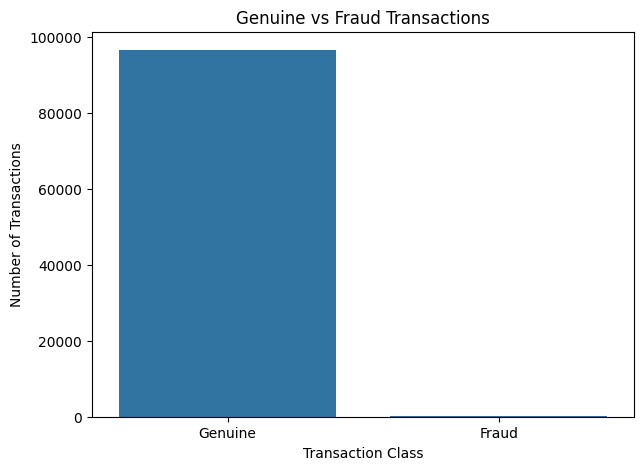

In [11]:
class_count = df_clean['Class'].value_counts()

print("Genuine Transactions:", class_count[0])
print("Fraud Transactions:", class_count[1])

fraud_percentage = (
    class_count[1] / len(df_clean)
) * 100

print(f"\nFraud Percentage: {fraud_percentage:.4f}%")

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='Class'
)

plt.title("Genuine vs Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ['Genuine', 'Fraud'])

plt.show()

Exploratory Data Analysis (EDA)

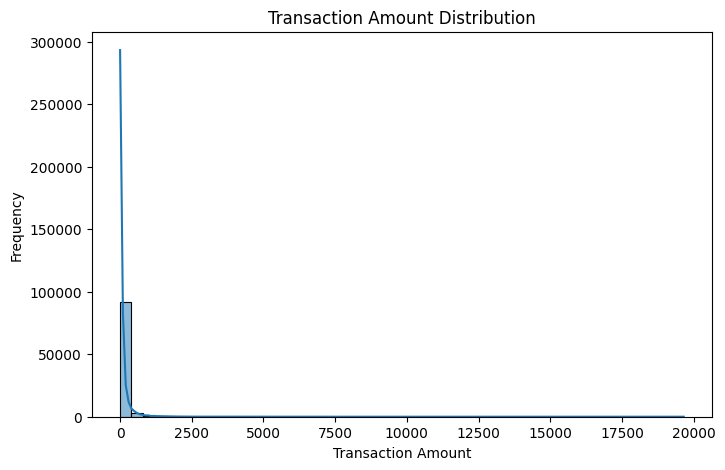

In [12]:
## 1. Transaction Amount Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Amount',
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

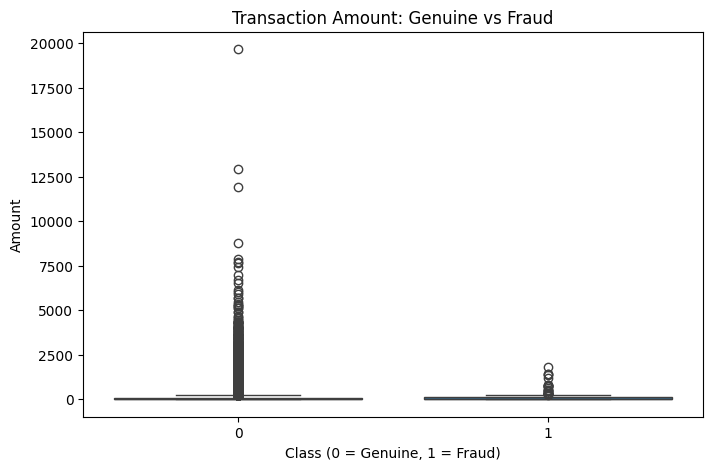

In [13]:
## 2. Genuine vs Fraud Amount
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Class',
    y='Amount'
)

plt.title("Transaction Amount: Genuine vs Fraud")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Amount")

plt.show()

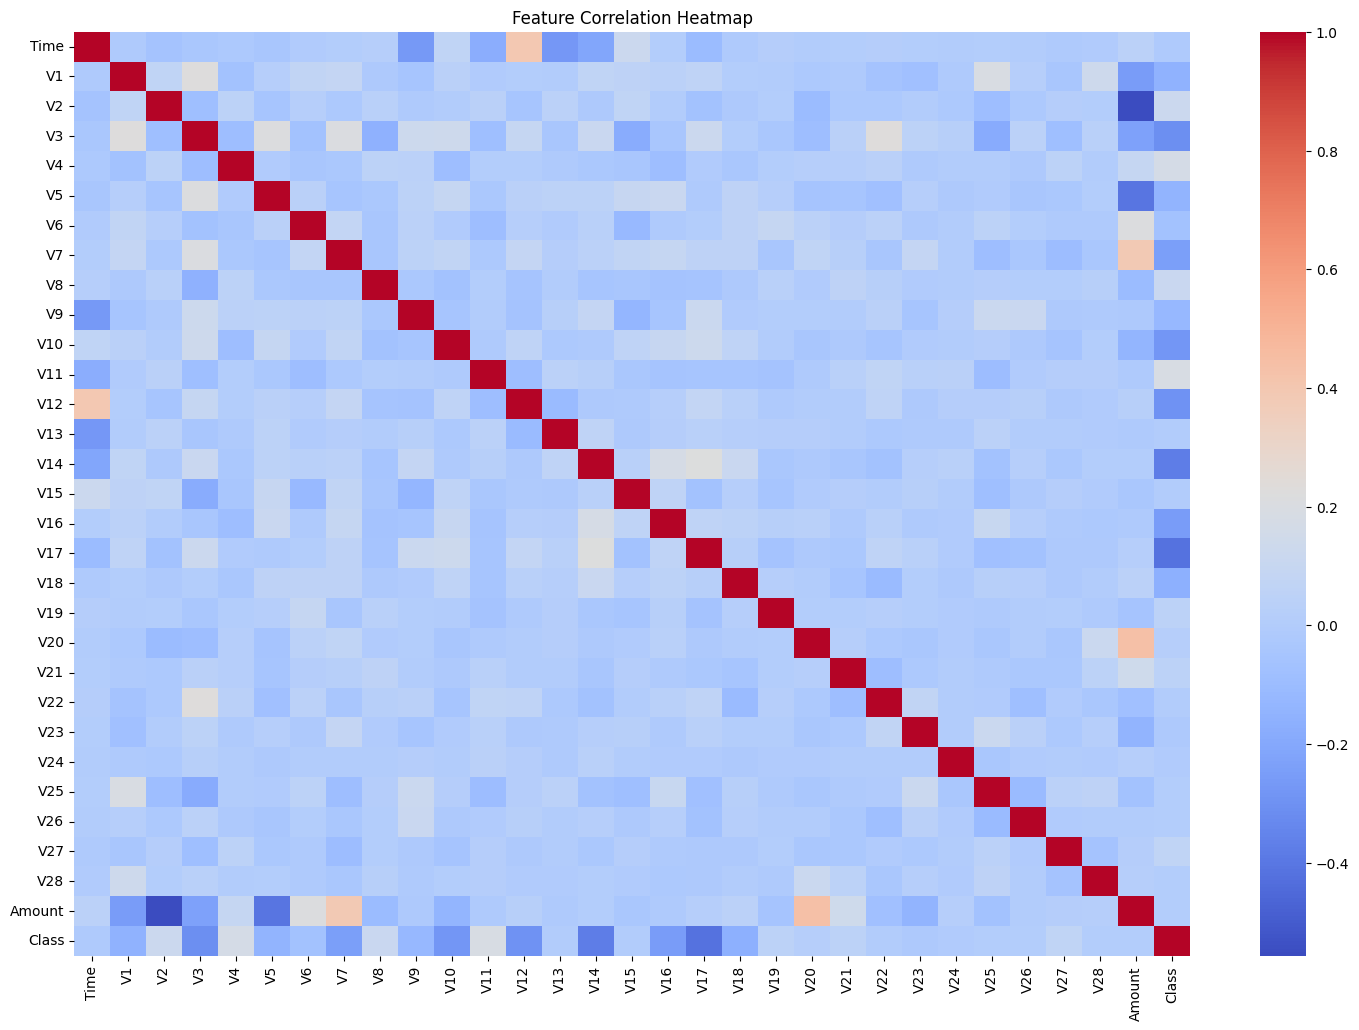

In [14]:
## 3. Correlation Heatmap
plt.figure(figsize=(18, 12))

correlation = df_clean.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False
)

plt.title("Feature Correlation Heatmap")

plt.show()

Separate features and target

In [15]:
x = df_clean.drop('Class', axis=1)

y = df_clean['Class']

print("Features Shape:", x.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(x.columns.tolist())



Features Shape: (96772, 30)
Target Shape: (96772,)

Feature Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


Split data into training, validation and test sets

In [16]:
# First split: 80% training + validation, 20% test
x_temp, x_test, y_temp, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 60% training, 20% validation
x_train, x_val, y_train, y_val = train_test_split(
    x_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Training Shape:", x_train.shape)
print("Validation Shape:", x_val.shape)
print("Testing Shape:", x_test.shape)

print("\nFraud Percentage:")

print("Training:", round(y_train.mean() * 100, 4), "%")
print("Validation:", round(y_val.mean() * 100, 4), "%")
print("Testing:", round(y_test.mean() * 100, 4), "%")

Training Shape: (58062, 30)
Validation Shape: (19355, 30)
Testing Shape: (19355, 30)

Fraud Percentage:
Training: 0.2291 %
Validation: 0.2325 %
Testing: 0.2273 %


Create machine learning models

In [17]:
models = {

    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]),

    "Balanced Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced_subsample',
        n_jobs=-1
    )
}

print("Models created successfully!")

Models created successfully!


Train all models

In [18]:
trained_models = {}

for name, estimator in models.items():

    print(f"Training {name}...")

    estimator.fit(x_train, y_train)

    trained_models[name] = estimator

    print(f"{name} trained successfully!\n")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Balanced Logistic Regression...
Balanced Logistic Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!



Evaluate models on validation data

In [19]:
results = []

for name, estimator in trained_models.items():

    y_pred = estimator.predict(x_val)

    y_proba = estimator.predict_proba(x_val)[:, 1]

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_val, y_proba)

    pr_auc = average_precision_score(y_val, y_proba)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='PR-AUC',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,Random Forest,0.9994,0.9722,0.7778,0.8642,0.9873,0.9126
0,Logistic Regression,0.9985,0.7667,0.5111,0.6133,0.9886,0.7862
1,Balanced Logistic Regression,0.9755,0.0819,0.9333,0.1505,0.9849,0.6842


Compare model performance

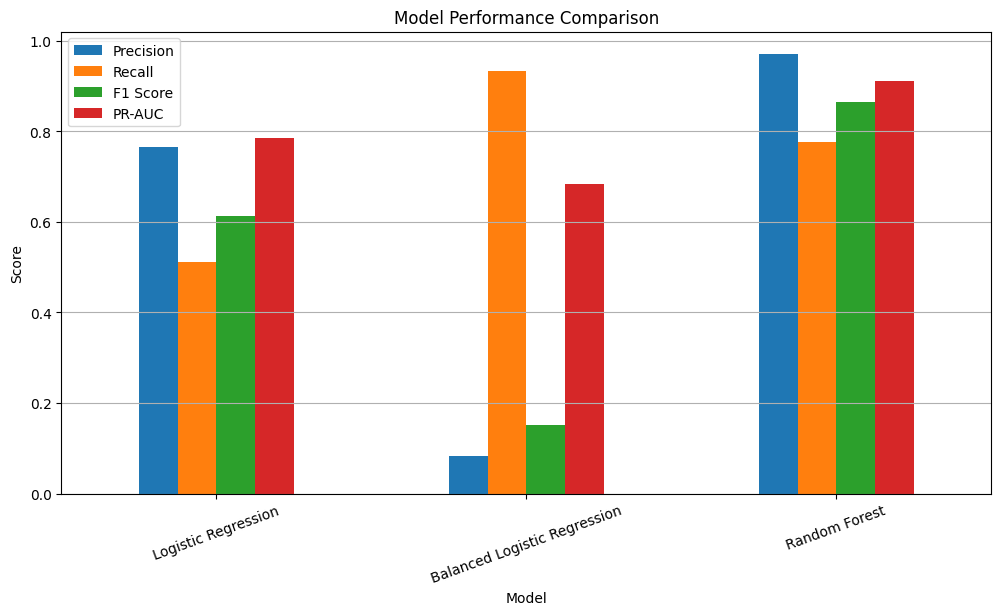

In [20]:
metrics = ['Precision', 'Recall', 'F1 Score', 'PR-AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc='best')
plt.grid(axis='y')

plt.show()

Select the best model using validation PR-AUC

In [21]:
best_model_name = results_df.sort_values(
    by='PR-AUC',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Random Forest


Tune prediction threshold on validation data

In [22]:
val_probabilities = best_model.predict_proba(x_val)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_val_pred = (
        val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.10,0.8077,0.9333,0.8660
1,0.15,0.8200,0.9111,0.8632
2,0.20,0.8542,0.9111,0.8817
3,0.25,0.8723,0.9111,0.8913
4,0.30,0.8864,0.8667,0.8764
5,0.35,0.9268,0.8444,0.8837
6,0.40,0.9500,0.8444,0.8941
7,0.45,0.9722,0.7778,0.8642
8,0.50,0.9722,0.7778,0.8642
9,0.55,0.9714,0.7556,0.8500


Find the best threshold

In [23]:
best_threshold_row = threshold_df.loc[
    threshold_df['F1 Score'].idxmax()
]

best_threshold = best_threshold_row['Threshold']

print("Best Threshold:", best_threshold)

print("Validation Precision:",
      round(best_threshold_row['Precision'], 4))

print("Validation Recall:",
      round(best_threshold_row['Recall'], 4))

print("Validation F1 Score:",
      round(best_threshold_row['F1 Score'], 4))

Best Threshold: 0.40000000000000013
Validation Precision: 0.95
Validation Recall: 0.8444
Validation F1 Score: 0.8941


Visualize threshold performance

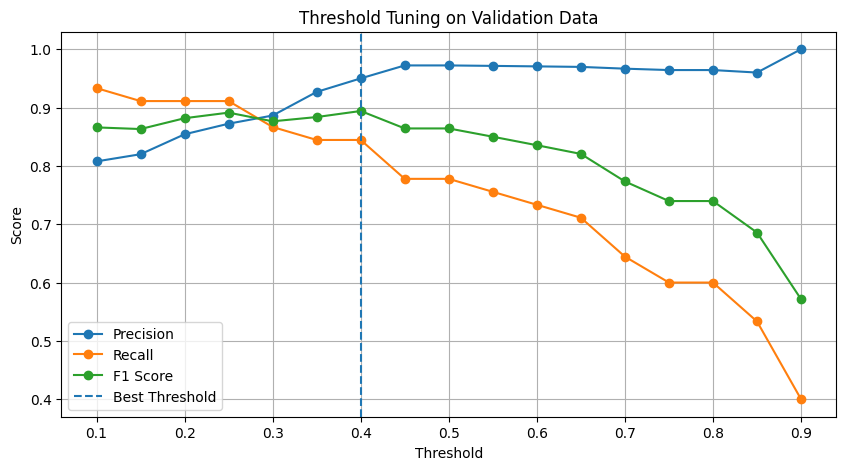

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.axvline(
    best_threshold,
    linestyle='--',
    label='Best Threshold'
)

plt.title("Threshold Tuning on Validation Data")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()

plt.show()

Final evaluation on test data

In [26]:
test_probabilities = best_model.predict_proba(x_test)[:, 1]

y_test_pred = (
    test_probabilities >= best_threshold
).astype(int)

print("Final Model:", best_model_name)
print("Final Threshold:", best_threshold)

print("\nFinal Test Results")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_test_pred), 4))

print("Recall:",
      round(recall_score(y_test, y_test_pred), 4))

print("F1 Score:",
      round(f1_score(y_test, y_test_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_probabilities), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, test_probabilities), 4))

Final Model: Random Forest
Final Threshold: 0.40000000000000013

Final Test Results
Accuracy: 0.9996
Precision: 0.9512
Recall: 0.8864
F1 Score: 0.9176
ROC-AUC: 0.9643
PR-AUC: 0.9087


Confusion matrix

Confusion Matrix:
[[19309     2]
 [    5    39]]


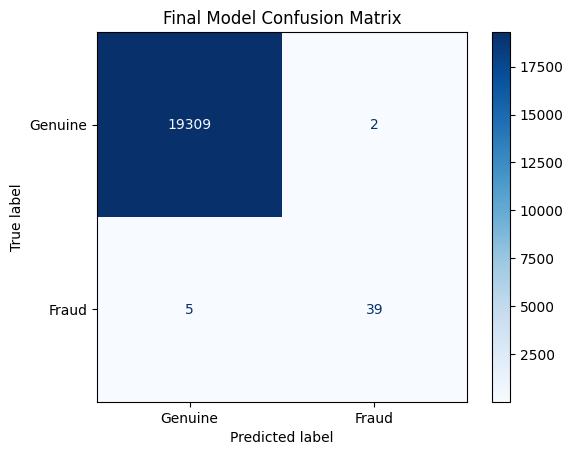

In [27]:
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Genuine', 'Fraud']
)

disp.plot(cmap='Blues')

plt.title("Final Model Confusion Matrix")

plt.show()

Classification report

In [28]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=['Genuine', 'Fraud']
    )
)

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     19311
       Fraud       0.95      0.89      0.92        44

    accuracy                           1.00     19355
   macro avg       0.98      0.94      0.96     19355
weighted avg       1.00      1.00      1.00     19355



Precision-Recall curve

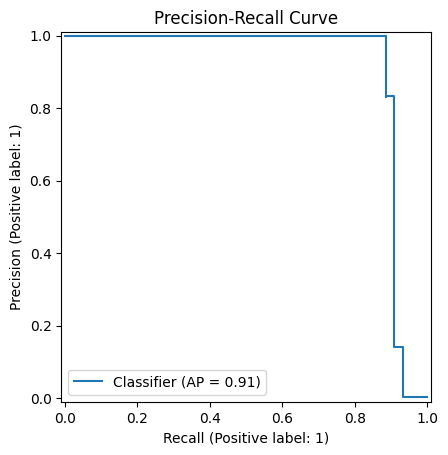

In [29]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("Precision-Recall Curve")

plt.show()

Feature importance (Random Forest only)

,Feature,Importance
14,V14,0.184479
12,V12,0.129807
10,V10,0.094579
17,V17,0.091755
3,V3,0.085297
4,V4,0.072474
16,V16,0.060133
11,V11,0.049341
2,V2,0.027336
27,V27,0.020370


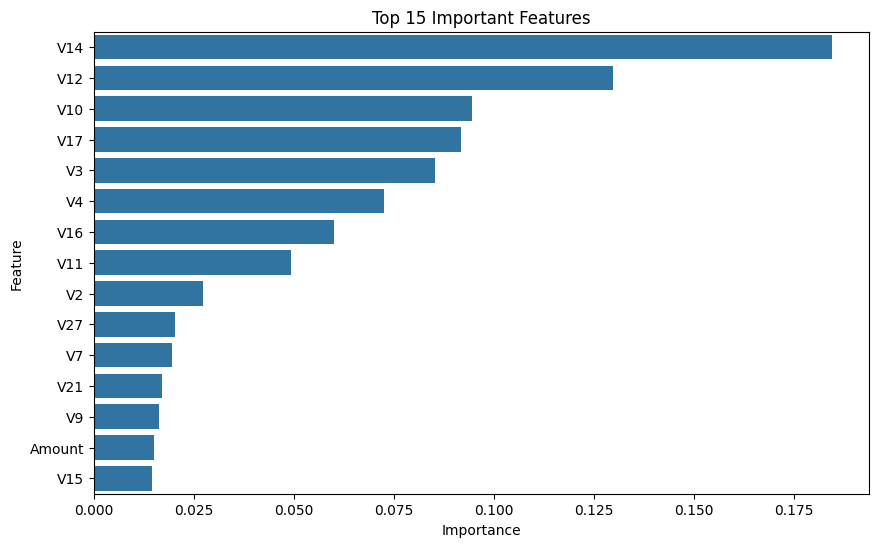

In [30]:
if best_model_name == "Random Forest":

    feature_importance = pd.DataFrame({
        'Feature': x.columns,
        'Importance': best_model.feature_importances_
    })

    feature_importance = feature_importance.sort_values(
        by='Importance',
        ascending=False
    )

    display(feature_importance.head(15))

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=feature_importance.head(15),
        x='Importance',
        y='Feature'
    )

    plt.title("Top 15 Important Features")

    plt.show()

else:
    print("Feature importance plot is available for Random Forest.")

Save the final trained model

In [31]:
model_artifact = {
    'model': best_model,
    'threshold': best_threshold,
    'model_name': best_model_name,
    'feature_columns': x.columns.tolist()
}

joblib.dump(
    model_artifact,
    'credit_card_fraud_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


Download the trained model

In [32]:
files.download('credit_card_fraud_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test the saved model with a sample transaction

In [33]:
loaded_artifact = joblib.load(
    'credit_card_fraud_model.pkl'
)

loaded_model = loaded_artifact['model']
loaded_threshold = loaded_artifact['threshold']
loaded_features = loaded_artifact['feature_columns']

# Take one transaction from test data
sample_transaction = x_test.iloc[[0]][loaded_features]

# Predict fraud probability
sample_probability = loaded_model.predict_proba(
    sample_transaction
)[0][1]

# Apply saved threshold
sample_prediction = int(
    sample_probability >= loaded_threshold
)

print("Fraud Probability:",
      round(sample_probability * 100, 2), "%")

print("Prediction:",
      "Fraudulent Transaction" if sample_prediction == 1
      else "Genuine Transaction")

Fraud Probability: 0.0 %
Prediction: Genuine Transaction
